In [1]:
import numpy as np
import scipy.stats as stats
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
PUBLIC_SRC = 'https://seshat.datasd.org/get_it_done_reports'
YEARS = [2021, 2022, 2023, 2024, 2025, 2026]
PRIVATE_CSV = 'data/gid_cases-001.csv'
ATTACH_CSV = 'data/public-attachments-cases.csv'
REFFERALS_CSV = 'data/referral data for UCSD-2026-11-02-23-09-16.csv'
WINDOW_START, WINDOW_END = '2023-01-01', '2026-10-01'

# Loading Datasets

## Loading public and private GID data

In [3]:
PUB_COLS = [
    'service_request_id', 'service_request_parent_id', 'date_requested', 'case_age_days',
    'case_record_type', 'service_name', 'service_name_detail', 'date_closed', 'status', 'case_origin', 'referred'
    ]

closed = pd.concat([pd.read_csv(f'{PUBLIC_SRC}/get_it_done_requests_closed_{y}_datasd.csv', usecols=PUB_COLS) for y in YEARS], ignore_index=True)
open_ = pd.read_csv(f'{PUBLIC_SRC}/get_it_done_requests_open_datasd.csv', usecols=PUB_COLS)

In [4]:
pub = pd.concat([closed, open_], ignore_index=True).drop_duplicates('service_request_id')

pub['date_requested'] = pd.to_datetime(pub['date_requested'])
pub['date_closed'] = pd.to_datetime(pub['date_closed'])

pub = pub[(pub['date_requested'] >= WINDOW_START) & (pub['date_requested'] < WINDOW_END)].copy()

In [5]:
PRIV_COLS = [
    'Case Reason', 'Last Modified Date', 'Parent Case ID', 'Parent Case ID', 'Case Number',
    'Owner ID', 'Last Modified By ID', 'Created By ID', 'Created Date',
    ]

RENAME = {t:t.lower().replace(' ', '_') for t in PRIV_COLS}
RENAME.update({'Status': 'private_status'})
priv = pd.read_csv(PRIVATE_CSV, usecols=list(RENAME), dtype=str).rename(columns=RENAME)

In [6]:
priv['case_number'] = pd.to_numeric(priv['case_number'], errors='coerce')
priv = priv.dropna(subset=['case_number'])
priv['case_number'] = priv['case_number'].astype(int)
priv.drop_duplicates('case_number', inplace=True)

priv['last_modified_date'] = pd.to_datetime(priv['last_modified_date'])
priv['owner_type'] = priv['owner_id'].str[:3].map({'005': 'worker', '00G': 'queue'}).fillna('other')
priv['modified_by_worker'] = priv['last_modified_by_id'].str[:3].eq('005')
priv['case_number'] = priv['case_number'].astype(float)
priv.drop(columns=['owner_id', 'last_modified_by_id'], inplace=True)

In [7]:
datasd = pub.merge(priv, left_on='service_request_id', right_on='case_number', how='left')

## Loading referrals data

In [8]:
REF_COLS = ['Internal Case Referral Flag', 'Internal Referral Count']

REF_RENAME = {t:t.lower().replace(' ', '_') for t in REF_COLS}
REF_RENAME.update({'Case Number': 'ref_case_number', 'Status': 'referral_status'})
referrals_info = pd.read_csv(REFFERALS_CSV, encoding='latin-1', usecols=list(REF_RENAME)).rename(columns=REF_RENAME)

In [9]:
df = datasd.merge(referrals_info, left_on='service_request_id', right_on='ref_case_number', how='left').drop(columns='ref_case_number')

In [10]:
df.head()

,service_request_id,service_request_parent_id,date_requested,case_age_days,case_record_type,service_name,service_name_detail,date_closed,status,case_origin,...,created_date,last_modified_date,parent_case_id,case_reason,private_status,owner_type,modified_by_worker,internal_case_referral_flag,internal_referral_count,referral_status
0,4470480,NaN,2023-10-20 08:24:00,0.0,ESD Complaint/Report,Illegal Dumping,Illegal Dumping,2023-10-20,Closed,Worker App,...,2023-10-20 08:24:41.000,2023-10-20 08:24:53,NaN,Problem resolved,Closed,queue,True,NaN,NaN,NaN
1,4470495,NaN,2023-10-20 08:28:00,0.0,ESD Complaint/Report,Illegal Dumping,Illegal Dumping,2023-10-20,Closed,Worker App,...,2023-10-20 08:28:31.000,2023-10-20 08:28:43,NaN,Problem resolved,Closed,queue,True,NaN,NaN,NaN
2,4470497,NaN,2023-10-20 08:28:00,3.0,Parking,Parking Violation,Red Zone,2023-10-23,Closed,Mobile,...,2023-10-20 08:28:43.000,2023-10-23 12:52:12,NaN,NaN,Closed,queue,True,0.0,0.0,Closed
3,4470499,4470478.0,2023-10-20 08:28:00,6.0,Storm Water Code Enforcement,Stormwater Code Enforcement,SWPP - Storm Water Polution Prevention,2023-10-26,Closed,Mobile,...,2023-10-20 08:28:52.000,2023-12-19 05:39:15,5008z000006VfAxAAK,Not a Storm Water Issue,Closed,worker,True,0.0,0.0,Closed
4,4470521,NaN,2023-10-20 08:33:00,0.0,TSW,Graffiti - Public,NaN,2023-10-20,Closed,Crew/Self Generated,...,2023-10-20 08:33:39.000,2025-03-18 12:57:47,NaN,Problem resolved,Closed,queue,True,NaN,NaN,NaN


In [11]:
df.fillna({'internal_case_referral_flag':0, 'internal_referral_count':0}, inplace=True)
df.drop(columns=['referral_status'], inplace=True)
df = df[(df['case_age_days'] >= 0) & (df['status'] == 'Closed') | (df['status'] == 'Referred')]

# Comparing `case_age_days` and `case_reason` based on internal* referrals

<!-- timeline (date fields) -->

### Is there a difference between ages (days) of cases based on if they are flagged for internal routing? What are the time (days) delays caused by many internal handoffs?

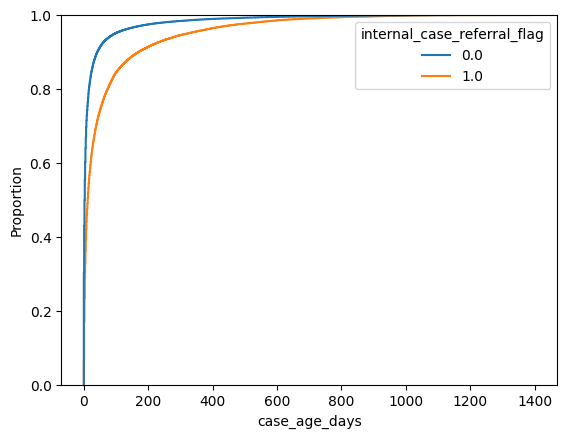

In [12]:
sns.ecdfplot(data=df, x='case_age_days', hue='internal_case_referral_flag')
plt.show()

In [13]:
internal_case_flag = df.loc[(df['internal_case_referral_flag'] == 1.), 'case_age_days']
no_case_flag = df.loc[(df['internal_case_referral_flag'] == 0.), 'case_age_days']
ks_stat, p_value = stats.ks_2samp(internal_case_flag, no_case_flag)

print(f'Test statistic: {ks_stat:.3f}, p-value: {p_value:.3e}')

Test statistic: 0.277, p-value: 0.000e+00


We reject the null hypothesis; the test results suggest that the distribution of case ages (in days) are different based on whether they were flagged for internal routing.

In [14]:
# Checking common service category requests 'Parking Violation'
internal_case_flag_pm = df.loc[(df['service_name'] == 'Parking Violation') & (df['internal_case_referral_flag'] == 1.), 'case_age_days']
no_case_flag_pm = df.loc[(df['service_name'] == 'Parking Violation') & (df['internal_case_referral_flag'] == 0.), 'case_age_days']
ks_stat_pm, p_val_pm = stats.ks_2samp(internal_case_flag_pm, no_case_flag_pm)

print(f'Test statistic: {ks_stat_pm:.3f}, p-value: {p_val_pm:.3e}')

Test statistic: 0.114, p-value: 4.130e-151


In [15]:
# Checking highly variable service category requests 'Other'
internal_case_flag_other = df.loc[(df['service_name'] == 'Other') & (df['internal_case_referral_flag'] == 1.), 'case_age_days']
no_case_flag_other = df.loc[(df['service_name'] == 'Other') & (df['internal_case_referral_flag'] == 0.), 'case_age_days']
ks_stat_ot, p_val_ot = stats.ks_2samp(internal_case_flag_other, no_case_flag_other)

print(f'Test statistic: {ks_stat_ot:.3f}, p-value: {p_val_ot:.3e}')

Test statistic: 0.735, p-value: 0.000e+00


In [16]:
services = ['Parking Violation', 'Other']
plot_data = df[(df['service_name'].isin(services))].copy()

plot_info = plot_data.groupby(['service_name', 'internal_case_referral_flag'])['case_age_days'].agg(mean='mean', median='median', top_percentile=lambda t: t.quantile(.9)).reset_index()

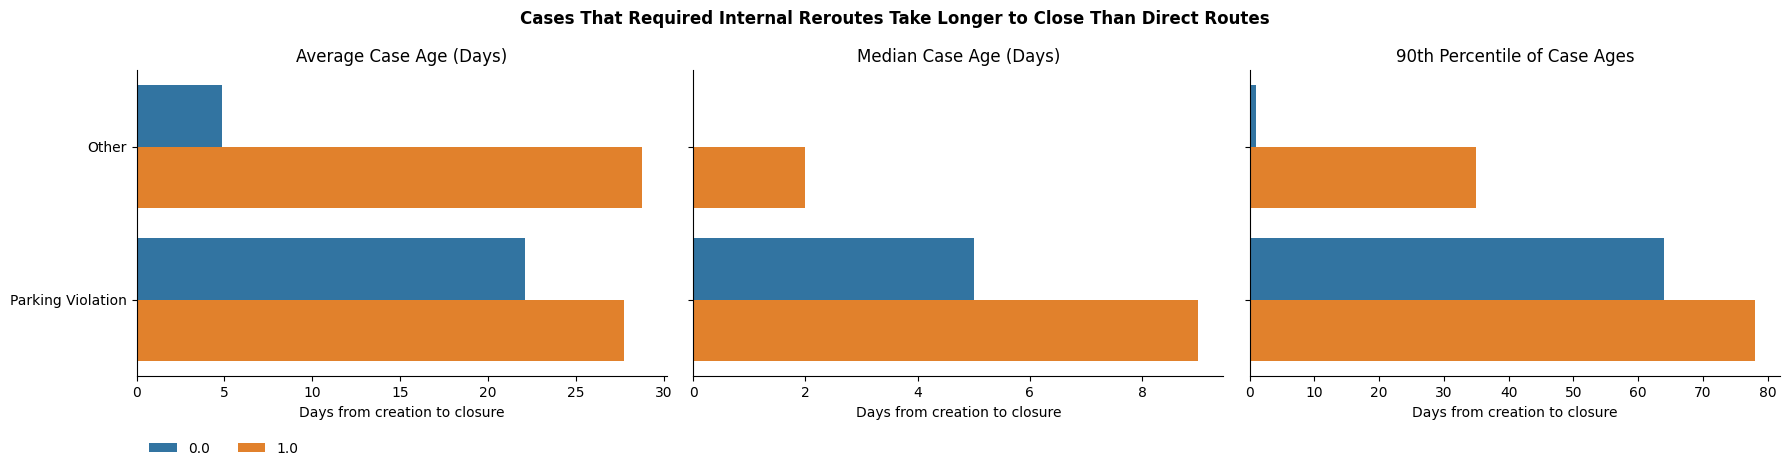

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
fig.suptitle('Cases That Required Internal Reroutes Take Longer to Close Than Direct Routes', fontweight='bold')

sns.barplot(data=plot_info, y='service_name', x='mean', hue='internal_case_referral_flag', ax=axes[0])
axes[0].set_title('Average Case Age (Days)')
axes[0].set_xlabel('Days from creation to closure')
axes[0].set_ylabel('')

sns.barplot(data=plot_info, y='service_name', x='median', hue='internal_case_referral_flag', ax=axes[1])
axes[1].set_title('Median Case Age (Days)')
axes[1].set_xlabel('Days from creation to closure')
axes[1].set_ylabel('')

sns.barplot(data=plot_info, y='service_name', x='top_percentile', hue='internal_case_referral_flag', ax=axes[2])
axes[2].set_title('90th Percentile of Case Ages')
axes[2].set_xlabel('Days from creation to closure')
axes[2].set_ylabel('')

# Clean up redundant legends (keep only one on the first plot)
axes[1].get_legend().remove()
axes[2].get_legend().remove()
axes[0].legend(title='', loc='lower left', bbox_to_anchor=(0, -0.3), ncol=2, frameon=False)

# Remove top and right borders (spines) for a cleaner look
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### *What impacts do back-to-back internal handoffs have operationally\*? Do multiple internally routings affect outcomes?

In [18]:
# Mapper dictionary to simplify `case_reason` to `case_outcome` (5 values)

CODEBOOK = {
    "Misrouted indicator": [
        "Send back to intake", "Not a Storm Water Issue", "Not a Storm Water Violation",
        "Complaint Forwarded", "Refer Elsewhere", "Other Department", 
    ],
    "Duplicate": [
        "Duplicate Report", "Duplicate", "ESD Collections - Duplicate reports", 
        "Closed-Duplicate Case", "Close Dups", "Closed-Duplicate"
    ],
    "Gone on arrival / vanished": [
        "GOA", "Gone on Arrival", "Moved", "ESD Collections - Unable to locate", 
        "Unable to locate", "Unable to Locate - SWC", "Moved / Tidied", 
        "Flooding Subsided", "City Contractor Unable to Locate"
    ],
    "Dismissed / non-actionable": [
        "Could not Complete", "Cleared; No Trash", "Do Not Enforce", "No Violation", 
        "Private/Commercial property", "Closed – Insufficient Info", "No Violation Found", 
        "Legally Parked", "Closed-Not Accepted-Budget", "Evaluated; No action warranted",
        "No Discharge", "Non-Stormwater/Private", "City Contractor No Action Taken", 
        "Closed-Administrative Closure", "ESD Collections - Do Not Service", 
        "Insufficient Case Details", "Closed-No violation", "No issue found", "Profanity",
        "No Email", "ESD Collections - Wrong Week", "Delayed Operator Response",
        "Closed Customer", "Private Property", "ESD Collections - Timely Reporting",
        "STRO-More Info Not Provided", "STRO-No Enforcement", "Allowable Discharge",
        "Event In Compliance", "Channel – No Maintenance", "Closed-Void", "Feedback",
        "STRO-Outside City Jurisdiction", "PD Delay", "Known Outreach Area", 
        "Clean Up Denied", "Closed-Due to Budget", "Encampment on Private Property",
        "Request no longer needed", "Cleared Administratively", "Feedback Received",
        "Graffiti - Private", "Unable to contact requestor", "Service Not Provided"
    ],
    "Action taken": [
        "Externally Referred", "Outside City", "Closed-Referral",
        "PD issue not handled in Get It Done", "Problem resolved", "Compliance Achieved", 
        "Container Emptied", "Impounded", "Cleared and Cleaned", "Cited", 
        "Enforcement Action Taken", "Warned", "Issue Resolved", "City Contractor Resolved", 
        "Closed-Involuntary Compliance", "Problem Abated", "Repaired by City", 
        "Container Removed", "Contact Made", "Request for Resurfacing", "PUD SN Created",
        "Cleared - ESD Cleanup Pending", "Customer Contacted", "Service Provider",
        "Resolved", "Assigned to User", "Closed-Voluntary Compliance",
        "Pending coordination", "Case Open in Accela", "Projects queue", "Revisit",
        "Crew Job Submitted", "Community Relations Officer", "Complete", "Planned Work",
        "Problem Fixed", "STRO-Noise Complaint (People)", "Investigation (Non-Stormw Asset)",
        "Temporary repair", "Provided requested information", "Marked for 72 Hour",
        "Channel – Minor", "Closed-Alternative Compliance", 
        "STRO-Host or Guest Conflict (NCRC)", "Enforcement Feedback", 
        "Active Investigation", "Clean Up Completed", "Sweeping request (Non-Emergency)",
        "Completed", "Blockage Removed", "Closed-Nuisance Referral", "Closed-Referred",
        "Litter", "Encampment on City Property or ROW", "ESD Cleanup", "TED Request Needed"
    ]
}

In [19]:
outcome_palette = {
    'Action taken': '#006989',
    'Gone on arrival / vanished': '#C45700',
    'Duplicate': '#F18F01',
    'Misrouted indicator': '#FFB85C',
    'Dismissed / non-actionable': '#FFEED6'
}

reason_map = {reason: keys for keys, vals in CODEBOOK.items() for reason in vals}

df['case_outcome'] = df['case_reason'].map(reason_map)

In [20]:
reason_map = {reason: keys for keys, vals in CODEBOOK.items() for reason in vals}

df['case_outcome'] = df['case_reason'].map(reason_map)

> Are internal referrals tied to specific service categories?

In [21]:
service_counts = df['service_name'].value_counts()
contingency_table = pd.crosstab(df.loc[df['service_name'].isin(service_counts[service_counts >= 30].index), 'service_name'], df.loc[df['service_name'].isin(service_counts[service_counts >= 30].index), 'internal_case_referral_flag'])
chi2_stat, p_val, dof, expected = stats.chi2_contingency(contingency_table)
print(f'Test statistic: {chi2_stat:.3f}, p-value: {p_val:.3e}, DOF: {dof}')

Test statistic: 259719.584, p-value: 0.000e+00, DOF: 38


We reject the null: specific categories are likely to be flagged for internal referrals.

> Does the number of internal referrals affect the case outcome?

In [22]:
contingency_table = pd.crosstab(df['internal_referral_count'], df['case_outcome'])
chi2_stat, p_val, dof, expected = stats.chi2_contingency(contingency_table)
print(f'Test statistic: {chi2_stat:.3f}, p-value: {p_val:.3e}, DOF: {dof}')

Test statistic: 22816.219, p-value: 0.000e+00, DOF: 52


This result implies that the number of internal referrals are associated with case outcomes.

<!-- If internal referrals are also related response/service delays, then this delay (in ages) means the case outcome, upon arrival, may change within this timeframe. -->

# `internal_referral_count` Analysis

In [23]:
import statsmodels.formula.api as smf
from scipy import stats

In [24]:
mod = smf.ols(formula='case_age_days ~ C(internal_referral_count)', data=df).fit()
print(mod.summary())

                            OLS Regression Results                            
Dep. Variable:          case_age_days   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                  0.014
Method:                 Least Squares   F-statistic:                     1651.
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:59:25   Log-Likelihood:            -8.8385e+06
No. Observations:             1509118   AIC:                         1.768e+07
Df Residuals:                 1509104   BIC:                         1.768e+07
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Inte

From the open portal (https://data.sandiego.gov/help/articles/tips-getitdone-311-requests/): `case_record_type` in the data contains values that indicate the City group responsible for a problem. These don’t always map with a city department 1:1, but they offer an idea of which department might be responsible.

In [25]:
model = smf.ols(formula='case_age_days ~ internal_referral_count * C(case_record_type)', data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          case_age_days   R-squared:                       0.110
Model:                            OLS   Adj. R-squared:                  0.110
Method:                 Least Squares   F-statistic:                     8151.
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:59:35   Log-Likelihood:            -8.7608e+06
No. Observations:             1509118   AIC:                         1.752e+07
Df Residuals:                 1509094   BIC:                         1.752e+07
Df Model:                          23                                         
Covariance Type:            nonrobust                                         
                                                                                  coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------

In [26]:
buckets = [count.values for _, count in df.groupby('internal_referral_count')['case_age_days']]
hstat, pval = stats.kruskal(*buckets)
print('Kruskal-Wallis Test for Case Age by Referral Count')
print(f'statistic: {hstat:.3f}, p-value: {pval:.4e}')

Kruskal-Wallis Test for Case Age by Referral Count
statistic: 47648.896, p-value: 0.0000e+00


- The Kruskal-Wallis test proves that case resolution time is associated with the number of internal referrals,
- the OLS models show that any case with no internal referrals take an average 27 days to be resolved, which increases as more internal referrals occur (over 50 days for cases with 3 or more internal referrals),
- `Neighborhood Policing`, `Parking`, `ESD Complaint` departments significantly quicker than the average resolution time.

**Net Delays by Department:**

- Traffic Engineering = 21.75 days for every addtional referral,
- TSW = 21.37 days,
- ESD Abatement = 1918 days,
- Storm Water Code Enforcement = 18.19 days,
- ESD Complaint/Report = 16.6 days,
- Parks and Rec. = 11.34 days,
- Neighborhood Policing = 10.73 days,
- Parking = 2.99 days

*(Departments/city groups not listed here did not have any significance.)*

In [27]:
mod = smf.ols(formula='case_age_days ~ internal_referral_count + C(service_name)', data=df).fit()
print(mod.summary())

                            OLS Regression Results                            
Dep. Variable:          case_age_days   R-squared:                       0.227
Model:                            OLS   Adj. R-squared:                  0.227
Method:                 Least Squares   F-statistic:                 1.005e+04
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:59:51   Log-Likelihood:            -8.6385e+06
No. Observations:             1506022   AIC:                         1.728e+07
Df Residuals:                 1505977   BIC:                         1.728e+07
Df Model:                          44                                         
Covariance Type:            nonrobust                                         
                                                                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------

- For any case, one internal referral adds on average 15.14 days to resolution time,
- The slowest services are `Vegetation Encroachment`, `Traffic Sign Maintenance`, and `PUD Code Compliance`.

In [28]:
service_avg_count = df.groupby('service_name')['internal_referral_count'].mean().reset_index()
service_avg_count.sort_values('internal_referral_count', ascending=False, inplace=True)
service_avg_count = service_avg_count.head(15)

/var/folders/sp/1qg6hw2572g23yxdgsh3gbkm0000gn/T/ipykernel_8417/47461082.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='internal_referral_count', y='service_name', data=service_avg_count, palette='crest_r')


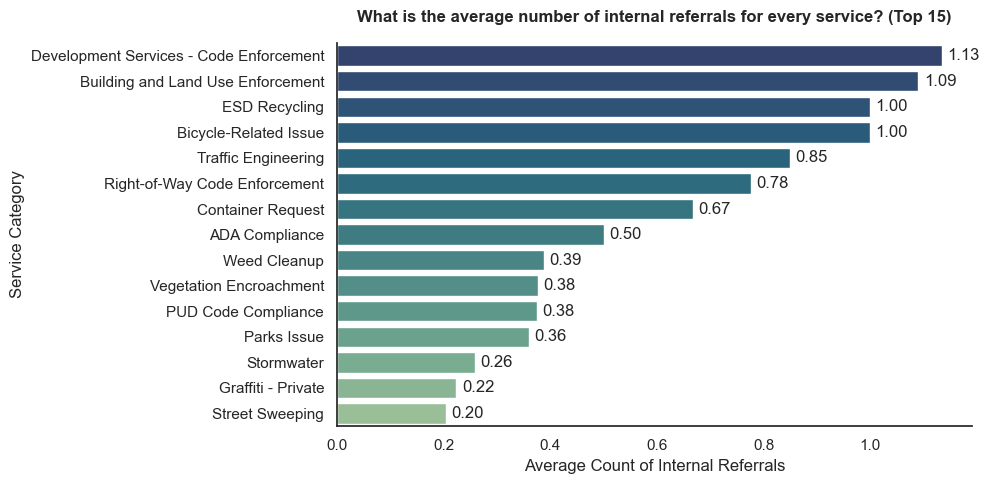

In [29]:
plt.figure(figsize=(10, 5))
sns.set_theme(style='white')

ax = sns.barplot(x='internal_referral_count', y='service_name', data=service_avg_count, palette='crest_r')

plt.title('What is the average number of internal referrals for every service? (Top 15)', fontweight='bold', pad=15)
plt.xlabel('Average Count of Internal Referrals')
plt.ylabel('Service Category')

for p in ax.patches:
    plt.text(p.get_width() + 0.01, p.get_y() + p.get_height()/2, 
             f'{p.get_width():.2f}', va='center')

sns.despine()
plt.tight_layout()
plt.show()

In [30]:
plot_data2 = df[df['internal_case_referral_flag'] == 1.]
avg_count = plot_data2.groupby('service_name')['internal_referral_count'].mean().reset_index()
avg_count.sort_values('internal_referral_count', ascending=False, inplace=True)
avg_count = avg_count.head(15)

In [31]:
department_avg_count = plot_data2.groupby('case_record_type')['internal_referral_count'].mean().reset_index()
department_avg_count.sort_values('internal_referral_count', ascending=False, inplace=True)
department_avg_count = department_avg_count.head(15)

/var/folders/sp/1qg6hw2572g23yxdgsh3gbkm0000gn/T/ipykernel_8417/3410879735.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='internal_referral_count', y='case_record_type', data=department_avg_count, palette='crest_r')


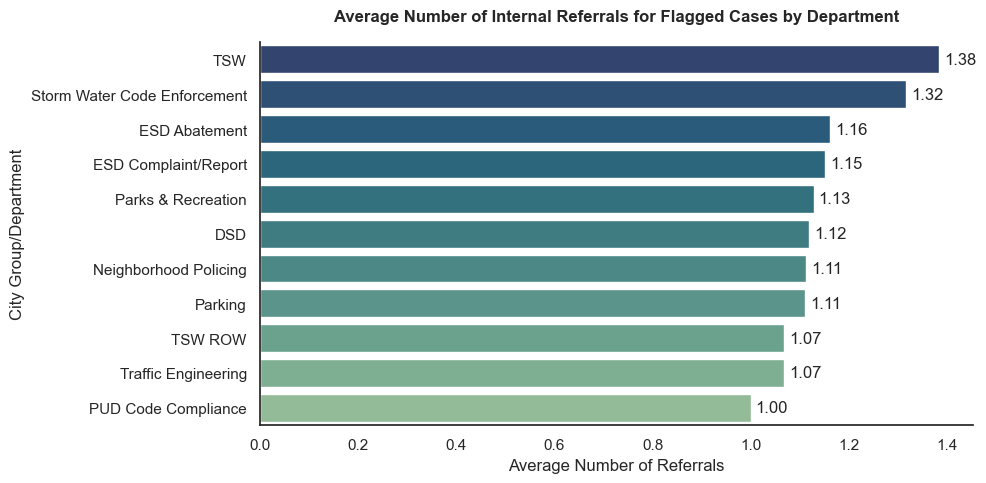

In [32]:
plt.figure(figsize=(10, 5))
sns.set_theme(style='white')

ax = sns.barplot(x='internal_referral_count', y='case_record_type', data=department_avg_count, palette='crest_r')

plt.title('Average Number of Internal Referrals for Flagged Cases by Department', fontweight='bold', pad=15)
plt.xlabel('Average Number of Referrals')
plt.ylabel('City Group/Department')

for p in ax.patches:
    plt.text(p.get_width() + 0.01, p.get_y() + p.get_height()/2, 
             f'{p.get_width():.2f}', va='center')

sns.despine()
plt.tight_layout()
plt.show()

In [33]:
outcome_palette = {
    'Action taken': '#006989',
    'Gone on arrival / vanished': '#C45700',
    'Duplicate': '#F18F01',
    'Misrouted indicator': '#FFB85C',
    'Dismissed / non-actionable': '#FFEED6'
}

reason_map = {reason: keys for keys, vals in CODEBOOK.items() for reason in vals}
df['case_outcome'] = df['case_reason'].map(reason_map)

In [34]:
data2 = df[(df['internal_case_referral_flag'] == 1.) & (df['internal_referral_count'].notna()) & (df['internal_referral_count'] > 0)]

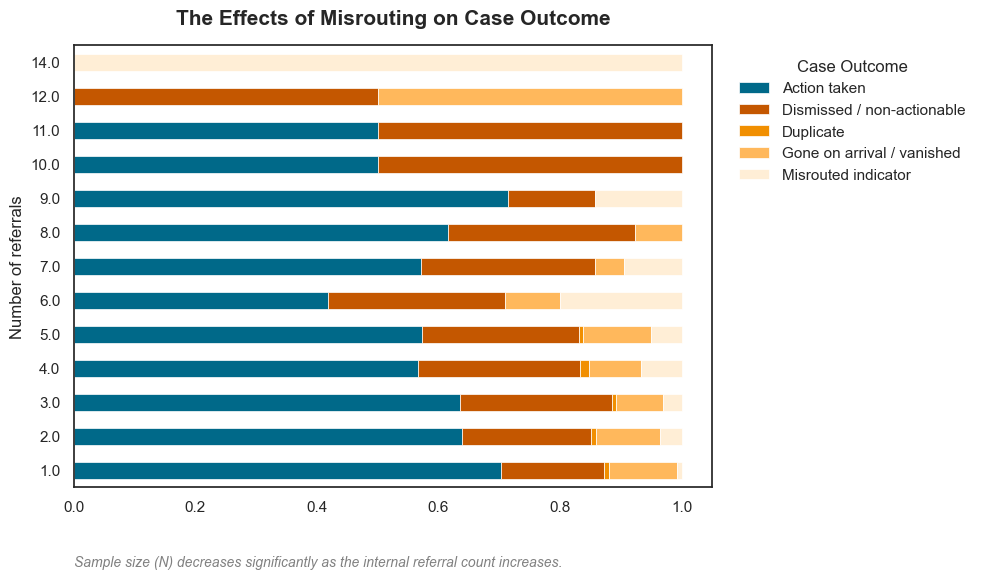

In [35]:
plot_data3 = data2.groupby('internal_referral_count')['case_outcome'].value_counts(normalize=True).unstack()
fig, ax = plt.subplots(figsize=(10, 6))
plot_data3.plot(kind='barh', stacked=True, ax=ax, linewidth=0.5, color=[outcome_palette[c] for c in outcome_palette])
ax.text(0, -0.18, 'Sample size (N) decreases significantly as the internal referral count increases.', transform=ax.transAxes, fontsize=10, style='italic', color='gray')
ax.set_title('The Effects of Misrouting on Case Outcome', pad=15, fontweight='bold', fontsize=15)
ax.set_ylabel('Number of referrals')
plt.legend(title='Case Outcome', bbox_to_anchor=(1.02, 1), frameon=False, loc='upper left')
plt.tight_layout()
plt.show()

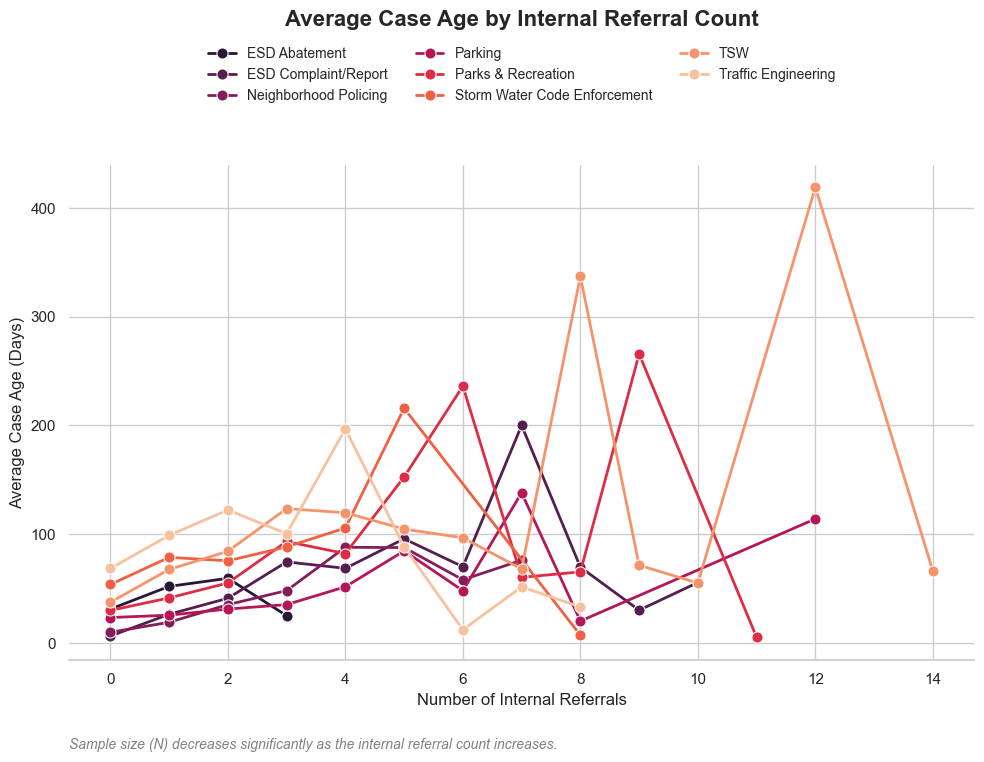

In [36]:
plot_data6 = df.copy()

line_data = plot_data6.groupby(['case_record_type', 'internal_referral_count'])['case_age_days'].mean().reset_index()
our_regression_depts = [
    'Traffic Engineering', 
    'TSW', 
    'ESD Abatement', 
    'Storm Water Code Enforcement', 
    'ESD Complaint/Report', 
    'Parks & Recreation', 
    'Neighborhood Policing', 
    'Parking'
]
line_data = line_data[line_data['case_record_type'].isin(our_regression_depts)]

plt.figure(figsize=(10, 8))
sns.set_theme(style='whitegrid') 

ax = sns.lineplot(data=line_data, x='internal_referral_count', y='case_age_days', hue='case_record_type', marker='o', markersize=8, linewidth=2, palette='rocket')

plt.title('Average Case Age by Internal Referral Count', fontsize=16, fontweight='bold', pad=100, loc='center')
plt.xlabel('Number of Internal Referrals', fontsize=12) 
plt.ylabel('Average Case Age (Days)', fontsize=12) 

plt.legend(
    title='',
    bbox_to_anchor=(0.5, 1.10),
    loc='lower center',
    ncol=3,                     
    frameon=False,              
    fontsize=10
)

ax.text(0, -0.18, 'Sample size (N) decreases significantly as the internal referral count increases.', transform=ax.transAxes, fontsize=10, style='italic', color='gray')

sns.despine(left=True, bottom=False, right=True, top=True)
plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

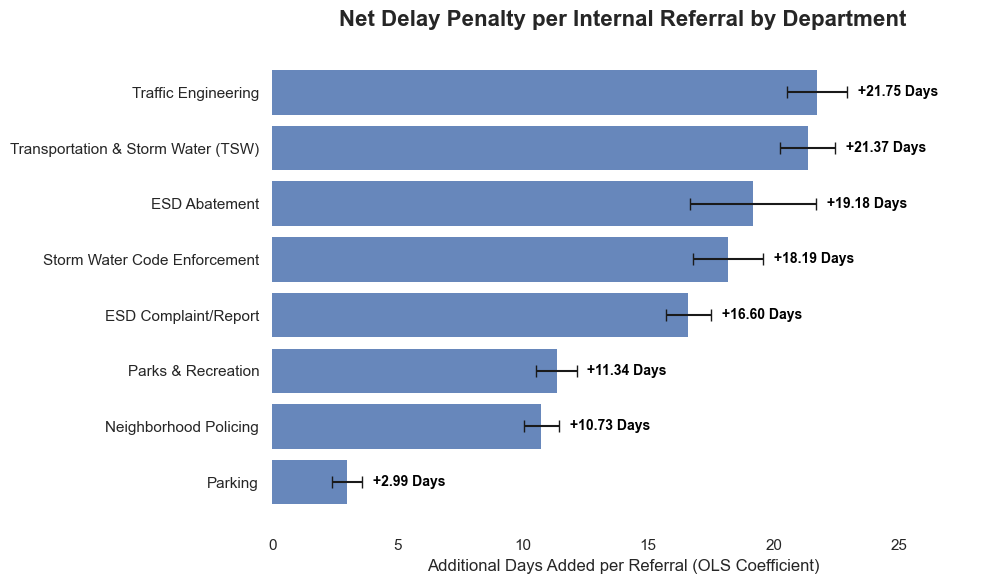

In [37]:
coef_data = pd.DataFrame({
    'department': [
        'Traffic Engineering', 
        'Transportation & Storm Water (TSW)', 
        'ESD Abatement', 
        'Storm Water Code Enforcement', 
        'ESD Complaint/Report', 
        'Parks & Recreation', 
        'Neighborhood Policing', 
        'Parking'
    ],
    'net_delay_days': [21.75, 21.37, 19.18, 18.19, 16.60, 11.34, 10.73, 2.99],
    'error_margin': [1.2, 1.1, 2.5, 1.4, 0.9, 0.8, 0.7, 0.6] 
})
coef_data = coef_data.sort_values(by='net_delay_days', ascending=True)

plt.figure(figsize=(10, 6))
sns.set_theme(style='white')
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    y=coef_data['department'], 
    width=coef_data['net_delay_days'], 
    xerr=coef_data['error_margin'], 
    edgecolor='none',
    alpha=0.85,
    capsize=4
)

plt.title('Net Delay Penalty per Internal Referral by Department', fontsize=16, fontweight='bold', pad=16)
plt.xlabel('Additional Days Added per Referral (OLS Coefficient)', fontsize=12)
plt.ylabel('', fontsize=12)

ax.bar_label(
    bars, 
    fmt=' +%.2f Days', 
    padding=5,
    fontsize=10, 
    fontweight='bold',
    color='black'
)

plt.xlim(0, 28)
sns.despine(left=True, bottom=True, right=True, top=True)
plt.tight_layout()
plt.show()